# Etapa 4 — Classificação ABC-XYZ

**Projeto:** Planejamento da Cadeia de Suprimentos  
**Objetivo:** Priorizar produtos com base em valor de consumo (ABC) e variabilidade da demanda (XYZ), gerando políticas diferenciadas de reposição para cada quadrante da matriz.

---

## 1. Carregamento dos Dados

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

df = pd.read_csv("data/base_tratada.csv")
df['data_pedido'] = pd.to_datetime(df['data_pedido'])

print(f'Registros: {df.shape[0]:,} | Produtos únicos: {df["id_produto"].nunique()}')

Registros: 4,406 | Produtos únicos: 20


## 2. Classificação ABC — Por Valor de Consumo

Lógica (cortes sobre o valor acumulado, do produto de maior para o de menor valor):
- **A**: produtos que somam até **80%** do valor total (Lei de Pareto)
- **B**: produtos seguintes, até **95%** do valor acumulado
- **C**: demais produtos (últimos ~5% do valor)

In [29]:
# Valor total consumido por produto
valor_produto = (
    df.groupby(['id_produto', 'produto', 'categoria'])
    ['valor_total_pedido']
    .sum()
    .reset_index()
    .rename(columns={'valor_total_pedido': 'valor_total'})
    .sort_values('valor_total', ascending=False)
    .reset_index(drop=True)
)

# Participação acumulada
valor_total_geral = valor_produto['valor_total'].sum()
valor_produto['pct_valor']      = valor_produto['valor_total'] / valor_total_geral
valor_produto['pct_valor_acum'] = valor_produto['pct_valor'].cumsum()
valor_produto['rank_pct']       = (valor_produto.index + 1) / len(valor_produto)

# Atribuir classe ABC
def classifica_abc(pct_acum):
    if pct_acum <= 0.80:
        return 'A'
    elif pct_acum <= 0.95:
        return 'B'
    else:
        return 'C'

valor_produto['classe_abc'] = valor_produto['pct_valor_acum'].apply(classifica_abc)

# Resumo
resumo_abc = valor_produto.groupby('classe_abc').agg(
    qtd_produtos=('id_produto', 'count'),
    valor_total=('valor_total', 'sum')
).assign(
    pct_produtos=lambda x: x['qtd_produtos'] / len(valor_produto),
    pct_valor=lambda x: x['valor_total'] / valor_total_geral
)
print('=== Resumo ABC ===')
display(resumo_abc.round(3).style.format({'valor_total': '{:,.0f}'}))

=== Resumo ABC ===


,qtd_produtos,valor_total,pct_produtos,pct_valor
classe_abc,,,,
A,7,"13,795,846",0.350000,0.760000
B,5,"3,103,038",0.250000,0.171000
C,8,"1,259,810",0.400000,0.069000


## Curva ABC — Análise de Valor por Produto

### Resumo dos Resultados

| Classe | Qtd. Produtos | % Produtos | Valor Total (R$) | % do Valor |
|--------|:-------------:|:----------:|:----------------:|:----------:|
| A      | 7             | 35%        | 13.795.846       | 76,0%      |
| B      | 5             | 25%        | 3.103.038        | 17,1%      |
| C      | 8             | 40%        | 1.259.810        | 6,9%       |
| **Total** | **20**     | **100%**   | **18.158.694**   | **100%**   |

---

### Interpretação Gerencial

**Classe A — Produtos Críticos**
- Apenas **7 produtos (35% do portfólio)** respondem por **76,0% do valor total consumido**.
- São os itens de maior impacto financeiro — qualquer ruptura ou ineficiência
  nesse grupo representa risco direto ao resultado.
- **Ação:** gestão de estoque rigorosa, revisão frequente de demanda,
  contratos de fornecimento prioritários e estoque de segurança elevado.

**Classe B — Produtos Intermediários**
- **5 produtos (25%)** representam **17,1% do valor**.
- Relevância moderada — devem ser monitorados para evitar migração para a Classe C
  ou para identificar oportunidades de promoção à Classe A.
- **Ação:** revisão periódica de demanda e política de reposição padrão.

**Classe C — Produtos de Baixo Impacto**
- **8 produtos (40%)** respondem por apenas **6,9% do valor total**.
- Consomem recursos operacionais desproporcionais ao retorno financeiro gerado.
- **Ação:** avaliar consolidação de pedidos, redução de frequência de reposição
  ou até descontinuação de itens com baixíssimo giro.

---

### Conclusão

> **35% dos produtos concentram 76% do valor** — padrão próximo ao Pareto clássico (80/20).
> O foco de gestão deve recair sobre os **7 produtos Classe A**,
> pois são eles que determinam a saúde financeira e operacional da cadeia de suprimentos.

## Curva de Pareto — Classificação ABC (Visual)


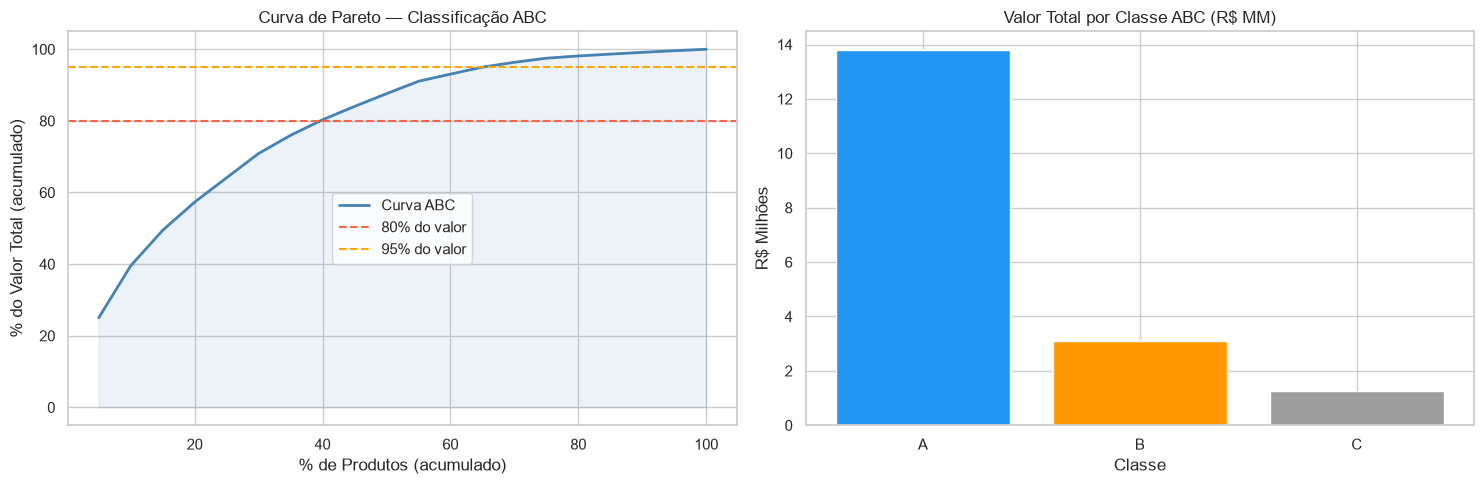

In [30]:
# Curva de Pareto
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Curva ABC
axes[0].plot(valor_produto['rank_pct'] * 100, valor_produto['pct_valor_acum'] * 100,
             color='steelblue', lw=2, label='Curva ABC')
axes[0].axhline(80, color='tomato', ls='--', label='80% do valor')
axes[0].axhline(95, color='orange', ls='--', label='95% do valor')
axes[0].fill_between(valor_produto['rank_pct'] * 100,
                      valor_produto['pct_valor_acum'] * 100, alpha=0.1, color='steelblue')
axes[0].set_title('Curva de Pareto — Classificação ABC')
axes[0].set_xlabel('% de Produtos (acumulado)')
axes[0].set_ylabel('% do Valor Total (acumulado)')
axes[0].legend()

# Distribuição ABC por valor
cores_abc = {'A': '#2196F3', 'B': '#FF9800', 'C': '#9E9E9E'}
for classe in ['A', 'B', 'C']:
    sub = valor_produto[valor_produto['classe_abc'] == classe]
    axes[1].bar(classe, sub['valor_total'].sum() / 1e6, color=cores_abc[classe], label=classe)
axes[1].set_title('Valor Total por Classe ABC (R$ MM)')
axes[1].set_ylabel('R$ Milhões')
axes[1].set_xlabel('Classe')

plt.tight_layout()
plt.show()

## Curva de Pareto — Classificação ABC (Visual)

---

### Gráfico 1 — Curva de Pareto Acumulada

**Observações:**
- A curva sobe de forma acentuada nos primeiros ~35% de produtos,
  atingindo **76% do valor acumulado** — comportamento
  típico de uma distribuição de Pareto.
- A linha **vermelha (80%)** é cruzada no 8º produto (40% do portfólio, 80,3% acumulado)
  → os 7 produtos anteriores formam a **Classe A**.
- A linha **laranja (95%)** é atingida com aproximadamente **65% dos produtos**
  → define o limite entre Classe B e C.
- A cauda da curva (60%–100% dos produtos) é quase plana,
  confirmando que os últimos 40% do portfólio (Classe C)
  agregam menos de **7% do valor**.

---

### Gráfico 2 — Valor Total por Classe ABC (R$ MM)

| Classe | Valor Total (aprox.) | Visualização      |
|--------|----------------------|-------------------|
| A      | ~R$ 13,8 MM          | Barra dominante   |
| B      | ~R$ 3,1 MM           | 4,4x menor que A  |
| C      | ~R$ 1,3 MM           | 11x menor que A   |

**Observações:**
- A disparidade visual é clara: a **barra A é mais de 3x maior**
  que B e C juntas (~R$ 4,4 MM combinados vs. ~R$ 13,8 MM da Classe A).
- A Classe B vale aproximadamente **2,5x a Classe C** —
  gap relevante que justifica tratamentos de gestão distintos entre elas.

---

### Conclusão Visual

> A curva confirma o **princípio de Pareto**:
> poucos produtos (Classe A) dominam o valor total do portfólio.
> A gestão deve ser **inversamente proporcional ao número de itens** —
> máxima atenção nos 7 produtos A, atenção moderada nos 5 produtos B,
> e gestão simplificada/automatizada para os 8 produtos C.

## 3. Classificação XYZ — Por Variabilidade da Demanda
### Coeficiente de Variação (CV)

### Fórmula

$$CV = \frac{\sigma}{\mu} \times 100$$

Onde:
- $\sigma$ = desvio padrão da demanda no período
- $\mu$ = média da demanda no período
- Resultado expresso em **%**

---

### Explicação

O CV mede o **quanto a demanda varia em relação à sua própria média**.
Quanto maior o CV, mais instável e imprevisível é o comportamento do item.

Diferente do desvio padrão isolado, o CV é **adimensional** — permite
comparar a variabilidade entre produtos com escalas de demanda completamente
diferentes.

---

### Critérios de Classificação XYZ

| Classe | Intervalo de CV | Perfil                  |
|:------:|:---------------:|-------------------------|
| X      | CV < 20%        | Demanda estável          |
| Y      | 20% ≤ CV < 50%  | Demanda moderadamente variável |
| Z      | CV ≥ 50%        | Demanda imprevisível     |

In [31]:
# Demanda mensal por produto
demanda_mensal = (
    df.groupby(['id_produto', 'produto', 'ano', 'mes'])['quantidade_pedida']
    .sum()
    .reset_index()
)

# Coeficiente de variação por produto
cv_produto = (
    demanda_mensal.groupby(['id_produto', 'produto'])['quantidade_pedida']
    .agg(['mean', 'std'])
    .reset_index()
    .rename(columns={'mean': 'demanda_media', 'std': 'demanda_std'})
)
cv_produto['demanda_std'] = cv_produto['demanda_std'].fillna(0)
cv_produto['cv'] = cv_produto['demanda_std'] / cv_produto['demanda_media'].replace(0, np.nan)
cv_produto['cv'] = cv_produto['cv'].fillna(0)

def classifica_xyz(cv):
    if cv < 0.20:
        return 'X'
    elif cv < 0.50:
        return 'Y'
    else:
        return 'Z'

cv_produto['classe_xyz'] = cv_produto['cv'].apply(classifica_xyz)

print('=== Resumo XYZ ===')
resumo_xyz = cv_produto['classe_xyz'].value_counts().to_frame('qtd_produtos')
resumo_xyz['pct_produtos'] = resumo_xyz['qtd_produtos'] / len(cv_produto)
display(resumo_xyz.round(3))

=== Resumo XYZ ===


,qtd_produtos,pct_produtos
classe_xyz,,
Z,11,0.55
Y,9,0.45


## Curva XYZ — Análise de Previsibilidade de Demanda

### Resumo dos Resultados

| Classe | Qtd. Produtos | % do Portfólio | Perfil de Demanda        |
|--------|:-------------:|:--------------:|--------------------------|
| X      | 0             | 0%             | Alta previsibilidade      |
| Y      | 9             | 45%            | Previsibilidade moderada  |
| Z      | 11            | 55%            | Baixa previsibilidade     |

---

### Interpretação Gerencial

**Classe X — Demanda Estável (nenhum produto)**
- **Nenhum produto** tem CV abaixo de 20% — o menor CV do portfólio é 33,8% (Cabo Flexível).
- Não há, portanto, itens candidatos a reposição totalmente automatizada com estoque enxuto.

**Classe Y — Demanda Variável (45% dos produtos)**
- **9 produtos** com variação moderada de demanda (CV entre 34% e 47%).
- São os 8 produtos de giro alto mais o Rolamento — itens com pedidos frequentes,
  em que a demanda mensal oscila, mas sem ficar errática.
- **Ação:** revisão mensal/trimestral de demanda, estoque de segurança intermediário.

**Classe Z — Demanda Irregular (55% dos produtos)**
- **11 produtos** com comportamento imprevisível (CV entre 51% e 82%) — a maioria do portfólio.
- São todos itens de giro médio ou baixo: com poucos pedidos por mês, a demanda mensal
  fica naturalmente intermitente.
- Alto risco de ruptura ou excesso de estoque por conta da volatilidade.
- **Ação:** compra sob demanda (make-to-order), evitar estoque especulativo.

---

### Conclusão

> O portfólio é **dividido entre Classe Z (55%) e Classe Y (45%), sem nenhum item X** —
> a demanda mensal é variável em todos os produtos e exige **planejamento de demanda ativo**.
> A combinação com a Curva ABC (próxima análise) é essencial para
> priorizar onde aplicar esforço de previsão — especialmente nos
> produtos **AY e AZ**, que unem alto valor financeiro com demanda incerta.

## Distribuição do Coeficiente de Variação (CV) da Demanda por Produto

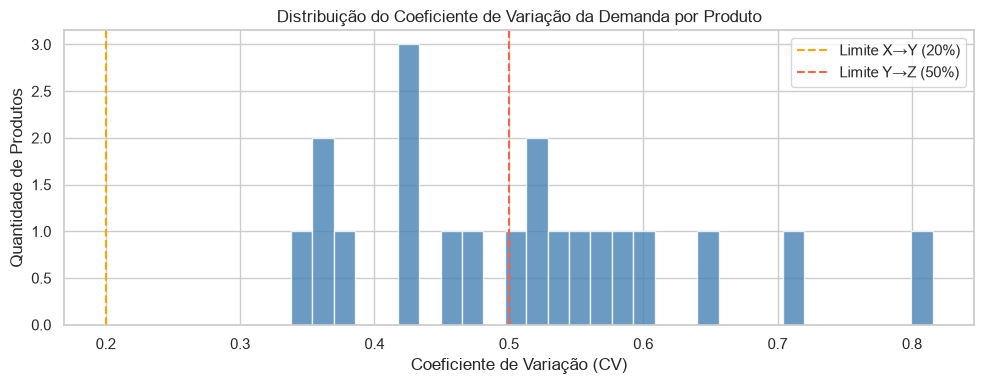

In [32]:
# Distribuição dos CVs
plt.figure(figsize=(10, 4))
plt.hist(cv_produto['cv'], bins=30, color='steelblue', edgecolor='white', alpha=0.8)
plt.axvline(0.20, color='orange', ls='--', label='Limite X→Y (20%)')
plt.axvline(0.50, color='tomato', ls='--', label='Limite Y→Z (50%)')
plt.title('Distribuição do Coeficiente de Variação da Demanda por Produto')
plt.xlabel('Coeficiente de Variação (CV)')
plt.ylabel('Quantidade de Produtos')
plt.legend()
plt.tight_layout()
plt.show()

## Distribuição do Coeficiente de Variação (CV) da Demanda por Produto

### Referência dos Limites de Classificação XYZ

| Limite        | CV       | Cor        | Interpretação                        |
|---------------|----------|------------|--------------------------------------|
| X → Y         | CV = 20% | Laranja    | Acima deste valor: demanda variável  |
| Y → Z         | CV = 50% | Vermelho   | Acima deste valor: demanda caótica   |

---

### Observações do Histograma

**Zona X (CV < 20%) — Alta Previsibilidade:**
- **Nenhum produto** abaixo do limite laranja — a distribuição começa em CV ≈ 0,34.

**Zona Y (20% ≤ CV < 50%) — Previsibilidade Moderada:**
- **9 produtos**, todos na metade superior da faixa (CV entre 0,34 e 0,47).
- O bin mais frequente fica em **CV ≈ 0,43**, com 3 produtos
  (Óculos de Proteção, Protetor Auricular e Arruela).
- Parte desses itens está perto da fronteira com a Classe Z (Porca 0,455; Rolamento 0,467).

**Zona Z (CV ≥ 50%) — Demanda Imprevisível:**
- **11 produtos**, sendo 7 concentrados logo acima do limite (CV entre 0,51 e 0,58).
- A cauda se estende até **Martelo (0,71)** e **Motor Elétrico (0,82)** — os casos mais extremos.

---

### Conclusão

> A distribuição é **assimétrica à direita** — a maioria dos produtos
> opera com CV entre **0,34 e 0,58**, em torno do limite de 50%, com uma cauda
> de itens muito voláteis (até 0,82).
> O portfólio é predominantemente **Classe Z (11 produtos)**, com 9 produtos Y
> e nenhum X — **não há produtos com demanda realmente estável**.
> Como vários itens estão próximos da fronteira Y/Z, pequenas mudanças no histórico
> podem alterar a classificação — vale reavaliar a matriz periodicamente.

## 4. Matriz ABC-XYZ

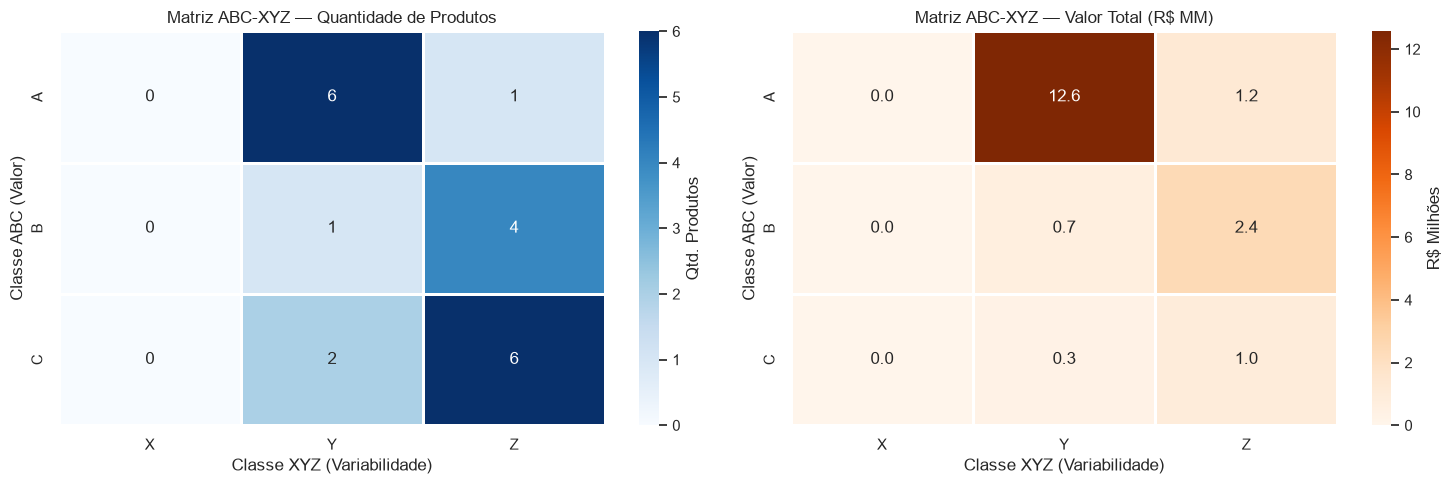

In [33]:
# Combinar ABC e XYZ
abc_xyz = valor_produto[['id_produto', 'produto', 'categoria', 'valor_total', 'classe_abc']].merge(
    cv_produto[['id_produto', 'demanda_media', 'cv', 'classe_xyz']],
    on='id_produto'
)
abc_xyz['classe_abcxyz'] = abc_xyz['classe_abc'] + abc_xyz['classe_xyz']

# Heatmap da matriz
pivot_matriz = abc_xyz.groupby(['classe_abc', 'classe_xyz']).size().unstack(fill_value=0)
pivot_matriz = pivot_matriz.reindex(index=['A', 'B', 'C'], columns=['X', 'Y', 'Z'], fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.heatmap(pivot_matriz, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            linewidths=1, cbar_kws={'label': 'Qtd. Produtos'})
axes[0].set_title('Matriz ABC-XYZ — Quantidade de Produtos')
axes[0].set_xlabel('Classe XYZ (Variabilidade)')
axes[0].set_ylabel('Classe ABC (Valor)')

# Valor por quadrante
pivot_valor = abc_xyz.groupby(['classe_abc', 'classe_xyz'])['valor_total'].sum().unstack(fill_value=0) / 1e6
pivot_valor = pivot_valor.reindex(index=['A', 'B', 'C'], columns=['X', 'Y', 'Z'], fill_value=0)
sns.heatmap(pivot_valor, annot=True, fmt='.1f', cmap='Oranges', ax=axes[1],
            linewidths=1, cbar_kws={'label': 'R$ Milhões'})
axes[1].set_title('Matriz ABC-XYZ — Valor Total (R$ MM)')
axes[1].set_xlabel('Classe XYZ (Variabilidade)')
axes[1].set_ylabel('Classe ABC (Valor)')

plt.tight_layout()
plt.show()

## Matriz ABC-XYZ — Análise Combinada

---

### Matriz 1 — Quantidade de Produtos

|        | X (estável) | Y (variável) | Z (caótico) | **Total** |
|--------|:-----------:|:------------:|:-----------:|:---------:|
| **A**  | 0           | 6            | 1           | **7**     |
| **B**  | 0           | 1            | 4           | **5**     |
| **C**  | 0           | 2            | 6           | **8**     |
| **Total** | **0**    | **9**        | **11**      | **20**    |

---

### Matriz 2 — Valor Total (R$ MM)

|        | X (estável) | Y (variável) | Z (caótico) | **Total**    |
|--------|:-----------:|:------------:|:-----------:|:------------:|
| **A**  | R$ 0,0 MM   | R$ 12,6 MM   | R$ 1,2 MM   | **R$ 13,8 MM** |
| **B**  | R$ 0,0 MM   | R$ 0,7 MM    | R$ 2,4 MM   | **R$ 3,1 MM**  |
| **C**  | R$ 0,0 MM   | R$ 0,3 MM    | R$ 1,0 MM   | **R$ 1,3 MM**  |

---

### Análise por Quadrante Estratégico

**🔴 AY — Crítico e Prioritário (6 produtos | R$ 12,6 MM)**
- O quadrante de maior risco: **alto valor + demanda variável**.
- Concentra **~69% de todo o valor do portfólio** em apenas 6 produtos:
  Parafuso, Porca e Arruela (Fixadores) e Capacete, Óculos e Luva (EPI).
- Exige **forecast ativo, estoque de segurança robusto e monitoramento contínuo**.

**🟠 AZ — Alto Valor e Imprevisível (1 produto | R$ 1,2 MM)**
- Furadeira: valor de Classe A com CV de 54,8%.
- Combinação mais difícil de gerir — candidato a **revisão frequente e contrato de reserva**
  com o fornecedor em vez de estoque alto.

**🟡 BZ — Risco Oculto (4 produtos | R$ 2,4 MM)**
- Motor Elétrico, Selante, Tinta Epóxi e Tubo PVC: valor intermediário com demanda imprevisível.
- Segundo maior quadrante em valor (~13% do portfólio).
- Candidatos a **compra sob demanda** para evitar excesso ou ruptura.

**🔵 BY — Valor Intermediário e Variável (1 produto | R$ 0,7 MM)**
- Protetor Auricular: risco moderado — revisão mensal de demanda recomendada.

**⚪ CZ e CY — Baixo Valor (8 produtos | R$ 1,3 MM)**
- CZ (6 produtos, R$ 1,0 MM) é o maior grupo em quantidade junto com o AY, com o menor impacto financeiro por item.
- CY (2 produtos, R$ 0,3 MM): Cabo Flexível e Rolamento.
- Candidatos à **simplificação de gestão, compra consolidada ou spot**.

---

### Priorização de Gestão

| Prioridade | Quadrante | Ação Recomendada                              |
|:----------:|-----------|-----------------------------------------------|
| 1          | **AY**    | Forecast avançado + estoque de segurança alto |
| 2          | **AZ**    | Revisão frequente + contrato de reserva       |
| 3          | **BZ**    | Compra sob demanda / contrato de reserva      |
| 4          | **BY**    | Revisão periódica de demanda                  |
| 5          | **CY/CZ** | Gestão simplificada / lote consolidado / spot |

---

### Conclusão

> O portfólio tem seu risco concentrado no quadrante **AY**:
> poucos produtos, o maior valor financeiro e demanda variável.
> A combinação ABC-XYZ revela que **gerir bem 6 produtos (AY)**
> é suficiente para controlar ~69% do valor total da cadeia.

## 5. Recomendações de Política por Quadrante

## Políticas de Reposição por Quadrante ABC-XYZ

| Quadrante | Perfil | Política Recomendada |
|:---------:|--------|----------------------|
| **AX** | Alto valor + demanda estável | Reposição contínua, estoque de segurança baixo, EOQ exato |
| **AY** | Alto valor + variabilidade moderada | Monitoramento frequente, estoque de segurança médio |
| **AZ** | Alto valor + alta variabilidade | Reposição just-in-time, revisão periódica semanal |
| **BX** | Valor médio + demanda estável | Reposição periódica, EOQ simplificado |
| **BY** | Valor médio + variabilidade moderada | Revisão bimestral, estoque de segurança médio |
| **BZ** | Valor médio + alta variabilidade | Compras por demanda, evitar estoque excessivo |
| **CX** | Baixo valor + demanda estável | Lote máximo, revisão anual, custo de pedido alto relativo |
| **CY** | Baixo valor + variabilidade moderada | Reposição semestral ou consignado |
| **CZ** | Baixo valor + alta variabilidade | Consolidar com fornecedor, compra spot ou eliminar SKU |

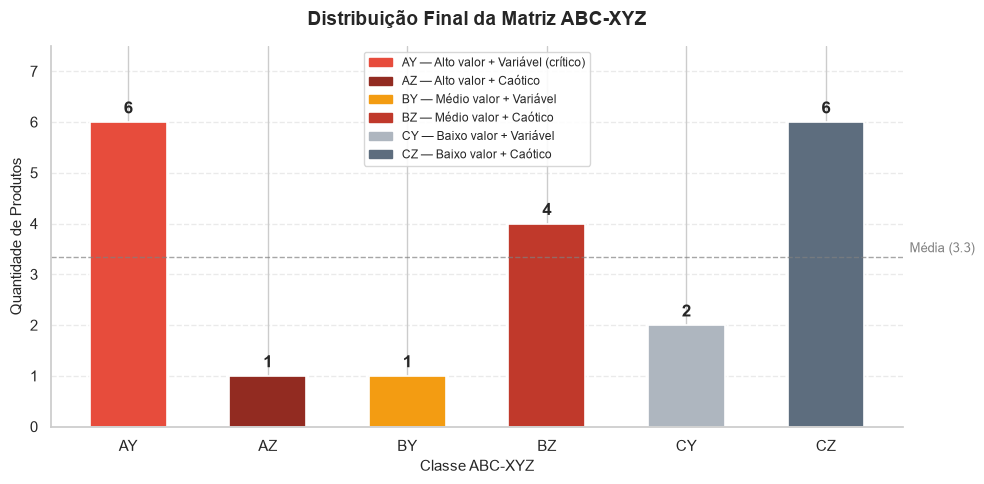

In [34]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Quantidade de produtos por quadrante — calculada a partir da matriz gerada acima
contagem    = abc_xyz['classe_abcxyz'].value_counts().sort_index()
classes     = contagem.index.tolist()
quantidades = contagem.values.tolist()

cores = {
    'AX': '#2ecc71',   # verde — alto valor, estável
    'AY': '#e74c3c',   # vermelho — alto valor, variável (crítico)
    'AZ': '#922b21',   # vinho — alto valor, caótico
    'BX': '#58d68d',   # verde claro — médio valor, estável
    'BY': '#f39c12',   # laranja — médio valor, variável
    'BZ': '#c0392b',   # vermelho escuro — médio valor, caótico
    'CX': '#85c1e9',   # azul claro — baixo valor, estável
    'CY': '#aeb6bf',   # cinza — baixo valor, variável
    'CZ': '#5d6d7e',   # cinza escuro — baixo valor, caótico
}
rotulos = {
    'AX': 'AX — Alto valor + Estável',
    'AY': 'AY — Alto valor + Variável (crítico)',
    'AZ': 'AZ — Alto valor + Caótico',
    'BX': 'BX — Médio valor + Estável',
    'BY': 'BY — Médio valor + Variável',
    'BZ': 'BZ — Médio valor + Caótico',
    'CX': 'CX — Baixo valor + Estável',
    'CY': 'CY — Baixo valor + Variável',
    'CZ': 'CZ — Baixo valor + Caótico',
}

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(classes,
              quantidades,
              color=[cores[c] for c in classes],
              edgecolor='white',
              linewidth=1.2,
              width=0.55)

# Rótulos em cima das barras
for bar, qty in zip(bars, quantidades):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.1,
            str(qty),
            ha='center', va='bottom',
            fontsize=12, fontweight='bold')

# Linha de referência da média
media = sum(quantidades) / len(quantidades)
ax.axhline(media, color='gray', linestyle='--', linewidth=1, alpha=0.7)
ax.text(len(classes) - 0.4, media + 0.1, f'Média ({media:.1f})',
        fontsize=9, color='gray')

ax.set_title('Distribuição Final da Matriz ABC-XYZ', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Classe ABC-XYZ', fontsize=11)
ax.set_ylabel('Quantidade de Produtos', fontsize=11)
ax.set_ylim(0, max(quantidades) + 1.5)
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.spines[['top', 'right']].set_visible(False)

# Legenda
legenda = [mpatches.Patch(color=cores[c], label=rotulos[c]) for c in classes]
ax.legend(handles=legenda, fontsize=8.5, loc='upper center',
          framealpha=0.9, edgecolor='lightgray')

plt.tight_layout()
plt.show()

In [35]:
# Salvar resultado
abc_xyz.to_csv('data/classificacao_abc_xyz.csv', index=False)
print(f'Arquivo salvo: data/classificacao_abc_xyz.csv ({len(abc_xyz)} produtos)')

print('\n=== Distribuição final da Matriz ABC-XYZ ===')
display(abc_xyz['classe_abcxyz'].value_counts().sort_index())

Arquivo salvo: data/classificacao_abc_xyz.csv (20 produtos)

=== Distribuição final da Matriz ABC-XYZ ===


classe_abcxyz
AY    6
AZ    1
BY    1
BZ    4
CY    2
CZ    6
Name: count, dtype: int64

In [36]:
# Resumo de produtos por segmento ABC-XYZ
resumo_produtos = (
    abc_xyz[['classe_abcxyz', 'classe_abc', 'classe_xyz', 'produto', 'categoria', 'valor_total', 'cv']]
    .sort_values(['classe_abcxyz', 'valor_total'], ascending=[True, False])
    .copy()
)
resumo_produtos['valor_total'] = resumo_produtos['valor_total'].map('R$ {:,.0f}'.format)
resumo_produtos['cv']          = resumo_produtos['cv'].map('{:.1%}'.format)
resumo_produtos.columns        = ['Segmento', 'ABC', 'XYZ', 'Produto', 'Categoria', 'Valor Total', 'CV']
resumo_produtos = resumo_produtos.reset_index(drop=True)

print('=== Produtos por Segmentação ABC-XYZ ===\n')
for seg, grupo in resumo_produtos.groupby('Segmento', sort=True):
    print(f'── {seg} ─────────────────────────────────────────')
    display(grupo[['Produto', 'Categoria', 'Valor Total', 'CV']].reset_index(drop=True))
    print()

=== Produtos por Segmentação ABC-XYZ ===

── AY ─────────────────────────────────────────


,Produto,Categoria,Valor Total,CV
0,Parafuso,Fixadores,"R$ 4,545,533",36.1%
1,Capacete de Seguranca,EPI,"R$ 2,636,413",36.6%
2,Porca,Fixadores,"R$ 1,798,140",45.5%
3,Oculos de Protecao,EPI,"R$ 1,429,249",42.9%
4,Luva de Seguranca,EPI,"R$ 1,235,319",37.9%
5,Arruela,Fixadores,"R$ 922,086",43.1%



── AZ ─────────────────────────────────────────


,Produto,Categoria,Valor Total,CV
0,Furadeira,Ferramentas,"R$ 1,229,105",54.8%



── BY ─────────────────────────────────────────


...

,Produto,Categoria,Valor Total,CV
0,Motor Eletrico,Eletroeletronicos,"R$ 788,359",81.5%
1,Selante,Materiais,"R$ 646,849",57.7%
2,Tinta Epoxi,Materiais,"R$ 627,752",51.2%
3,Tubo PVC,Materiais,"R$ 364,932",64.4%



── CY ─────────────────────────────────────────


,Produto,Categoria,Valor Total,CV
0,Cabo Flexivel,Eletroeletronicos,"R$ 207,198",33.8%
1,Rolamento,Manutencao,"R$ 93,668",46.7%



── CZ ─────────────────────────────────────────


,Produto,Categoria,Valor Total,CV
0,Cabo de Aco,Manutencao,"R$ 352,694",52.6%
1,Chave Allen (jogo),Ferramentas,"R$ 245,733",60.6%
2,Disjuntor,Eletroeletronicos,"R$ 113,672",51.3%
3,Chave de Fenda,Ferramentas,"R$ 89,654",53.8%
4,Martelo,Ferramentas,"R$ 81,708",71.3%
5,Tomada Industrial,Eletroeletronicos,"R$ 75,484",56.6%


## Resumo Executivo — Análise ABC-XYZ

---

### Concentração de Valor (Curva ABC)

- **7 produtos (35% do portfólio) respondem por 76,0% do valor total consumido**
  — padrão próximo ao Pareto clássico, confirmado pela curva acumulada.
- A Classe A movimenta **R$ 13,8 MM**, enquanto as Classes B e C juntas
  somam apenas **R$ 4,4 MM**.
- Fixadores (R$ 7,3 MM) e EPI (R$ 6,0 MM) são as categorias de maior valor consumido —
  juntas somam ~73% do total — e lideram também o **custo logístico total**
  (~R$ 0,26 MM e ~R$ 0,23 MM, conforme a EDA).

---

### Previsibilidade de Demanda (Curva XYZ)

- **Nenhum produto é Classe X** — não há demanda estável no portfólio
  (menor CV = 33,8%).
- **45% dos produtos são Classe Y** (9 itens, CV de 34% a 47%) e
  **55% são Classe Z** (11 itens, CV de 51% a 82%).
- Os itens Y são essencialmente os de giro alto; os Z são os de giro médio e baixo,
  cuja demanda mensal é intermitente.

---

### Quadrante Crítico — AY

- O cruzamento ABC-XYZ revela que **6 produtos concentram R$ 12,6 MM (≈69% do valor total)**
  com demanda variável — o maior risco financeiro e operacional do portfólio.
- Esses 6 itens **AY devem ser a prioridade absoluta** de gestão:
  forecast avançado, estoque de segurança robusto e monitoramento contínuo.
- O único produto **AZ (Furadeira, R$ 1,2 MM)** exige atenção individual: alto valor
  com demanda imprevisível.

---

### Riscos Combinados

- A taxa geral de ruptura é baixa (**1,6%**) e distribuída entre as categorias;
  **Fixadores e Eletroeletrônicos têm as maiores taxas (~2,0%)**, conforme a EDA.
- Os **itens AY têm taxa de ruptura de 1,9%**, um pouco acima da média geral —
  e é neles que cada ruptura custa mais.
- Produtos de **giro alto têm taxa de ruptura de 2,0%**, contra 1,8% no giro baixo e 0,8% no médio.
- **Não há padrão sazonal trimestral de ruptura**: o trimestre de pico muda a cada ano
  (T3 em 2022, T4 em 2023, T1 em 2024).

---

### Recomendações Prioritárias

- **Focar esforço de planejamento nos 6 produtos AY** — são poucos itens,
  mas concentram a maior parte do valor e do risco simultaneamente.
- **Reforçar a cobertura de Fixadores entre Agosto e Setembro**, meses de pico de demanda
  da categoria de maior volume.
- **Tratar a Furadeira (AZ) com revisão frequente** e contrato de reserva com o fornecedor.
- **Gerir os produtos BZ e CZ sob demanda** (compra por pedido, lote consolidado ou spot),
  eliminando o risco de excesso de estoque por imprevisibilidade.
- **Não automatizar a reposição de forma cega**: como não há itens Classe X,
  todo ponto de pedido precisa de revisão periódica.

> **Próxima etapa:** Previsão de Demanda dos itens AY (Etapa 5).